# Multimodal RAG 실습

대상 자료: 질병관리청 「손상예방 2023 No.3」 중 "직업손상" 특집 기사(6~20페이지, `data/invest.pdf`).
텍스트/표/이미지를 각각 추출하고 요약한 뒤, 다중 벡터 검색기로 관련 원문(텍스트·표·이미지)을 찾아
멀티모달 LLM이 최종 답변을 생성합니다.

실행 전 확인하세요:
1. 우측 상단 커널을 **"Python (multimodal-rag .venv)"** 로 선택했는지
2. 프로젝트 루트에 `.env`를 만들고 `OPENAI_API_KEY`를 설정했는지

## 0. 환경 검증

In [1]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "\u2717 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "\u2717 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: \u2717 미설치")

Python: 3.11.9
가상환경 경로: C:\workspace\MultimodalRag\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK


unstructured  : OK


chromadb      : OK
tiktoken      : OK
PIL           : OK


## 1. API 키 불러오기

In [2]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import os
from dotenv import load_dotenv

load_dotenv(ROOT / ".env")
openai_api_key = os.getenv("OPENAI_API_KEY")

if not openai_api_key:
    raise ValueError("OpenAI API 키가 없습니다. .env를 확인해주세요.")
print(f"API Key: {openai_api_key[:7]}...{openai_api_key[-4:]}")

API Key: sk-proj...Vq0A


## 2. 데이터 추출 (텍스트 / 표 / 이미지)

In [3]:
from src.extract import extract_pdf

texts, tables, image_paths = extract_pdf(ROOT / "data" / "invest.pdf")
print(f"텍스트 블록: {len(texts)}개")
print(f"표: {len(tables)}개")
print(f"이미지: {len(image_paths)}개")

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1


Cannot set stroke color: /'P0' is an invalid float value


Cannot set stroke color: /'P0' is an invalid float value


Cannot set stroke color: /'P0' is an invalid float value


Cannot set stroke color: /'P0' is an invalid float value


Cannot set stroke color: /'P0' is an invalid float value


... (6 outputs left out)

Cannot set stroke color: /'P0' is an invalid float value


Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 367/367 [00:00<00:00, 3858.36it/s]

텍스트 블록: 15개
표: 9개
이미지: 10개


In [4]:
# 표 하나를 실제 격자 모양(HTML)으로 확인
from IPython.display import HTML, Image, display

sample_table = next(t for t in tables if t.metadata.get("html"))
print(f"표 출처: {sample_table.metadata['source']} / {sample_table.metadata['page']}페이지")
display(HTML(sample_table.metadata["html"]))

표 출처: C:\workspace\MultimodalRag\data\invest.pdf / 7페이지


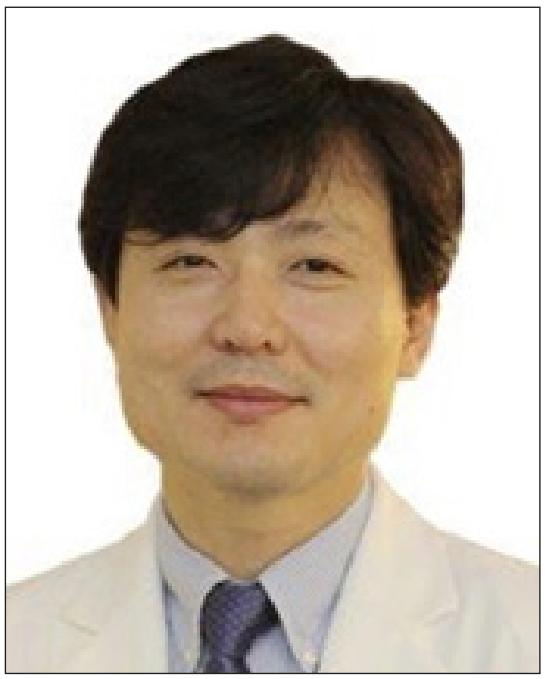

In [5]:
# 추출된 이미지 중 하나를 직접 확인
display(Image(filename=str(image_paths[0]), width=400))

## 3. 요약 생성 (텍스트·표 LLM 요약 / 이미지 VLM 요약)

In [6]:
from src.summarize import summarize_documents, summarize_images

text_summaries = summarize_documents(texts)
table_summaries = summarize_documents(tables)
image_originals, image_summaries = summarize_images(image_paths)

print("텍스트 요약 샘플:\n", text_summaries[0].page_content[:200])
print("\n표 요약 샘플:\n", table_summaries[0].page_content[:200])
print("\n이미지 요약 샘플:\n", image_summaries[0].page_content[:200])

텍스트 요약 샘플:
 **직업손상 및 산업재해 관련 법 제도 고찰 요약**

- **정의 구분**: 직업손상은 업무상 사고로 인한 손상, 질병, 사망을 포함하며, 국제 노동기구(ILO)는 이를 명확히 구분하고 있다. 한국에서는 업무상 재해를 사고와 질병으로 정의하지만, 일부 국가에서는 두 개념을 혼용하기도 한다.

- **산재보험의 사고와 질병**: 근로복지공단은 산업재해보상보

표 요약 샘플:
 업무상 사고 재해자 수는 92,383명, 사망자는 882명이다. 성별로는 남자가 77.1% (71,218명), 여자가 22.9% (21,165명)이다. 연령대별로는 50-59세가 29.0% (26,813명)로 가장 많고, 사망자는 60세 이상이 39.3% (347명)로 가장 높은 비율을 차지한다. 산업별로는 제조업이 25.0% (23,127명), 건설업이 

이미지 요약 샘플:
 이미지에는 한 남성의 얼굴이 보이며, 그는 흰색 의사 가운을 입고 있습니다. 배경은 흰색으로 설정되어 있습니다. 그의 머리는 짧고 어두운 색이며, 부드러운 표정을 짓고 있습니다. 이 이미지는 의료 분야와 관련이 있을 것으로 추측됩니다.


## 4. 다중 벡터 검색기 구축

비교를 위해 두 가지를 만듭니다: 텍스트만 쓰는 일반 RAG용 검색기와, 텍스트+표+이미지를 모두 쓰는
멀티모달 RAG용 검색기.

In [7]:
from src.chain import build_answer_chain
from src.retriever import create_multi_vector_retriever

# 멀티모달: 텍스트 + 표 + 이미지
mm_originals = texts + tables + image_originals
mm_summaries = text_summaries + table_summaries + image_summaries
multimodal_retriever = create_multi_vector_retriever(mm_originals, mm_summaries)
multimodal_chain = build_answer_chain(multimodal_retriever)

# 일반 RAG: 텍스트만
text_only_retriever = create_multi_vector_retriever(texts, text_summaries)
text_only_chain = build_answer_chain(text_only_retriever)

## 5. 질의응답 5건

In [8]:
QUESTIONS = [
    "손상 사고를 당한 사람들의 성별 비율은 어떻게 되나요?",
    "연령대별로 손상이 가장 많이 발생한 구간은 어디인가요?",
    "산업별 손상 발생 현황에서 가장 두드러지는 산업은 무엇인가요?",
    "그래프에 나타난 손상 발생 추이는 어떤 경향을 보이나요?",
    "직업손상과 관련한 국내외 법 제도에는 어떤 것들이 있나요?",
]

qa_results = []
for question in QUESTIONS:
    hits = multimodal_retriever.invoke(question)
    evidence_types = [hit.metadata.get("content_type", "text") for hit in hits]
    answer = multimodal_chain.invoke(question)
    qa_results.append({"question": question, "answer": answer, "evidence_types": evidence_types})
    print("Q:", question)
    print("A:", answer)
    print("근거 유형:", evidence_types)
    print("-" * 80)

Q: 손상 사고를 당한 사람들의 성별 비율은 어떻게 되나요?
A: 손상 사고를 당한 사람들의 성별 비율은 남성이 77.1% (71,218명)이고, 여성이 22.9% (21,165명)입니다.
근거 유형: ['text', 'table', 'text', 'text', 'text', 'text']
--------------------------------------------------------------------------------


Q: 연령대별로 손상이 가장 많이 발생한 구간은 어디인가요?
A: 자료에 따르면, 연령대별로 손상이 가장 많이 발생한 구간은 50-59세로, 이 연령대의 비율이 29.0%로 가장 높습니다. 다음으로 60-69세가 21.9%, 40-49세가 18.3%로 나타났습니다.
근거 유형: ['text', 'text', 'text', 'text', 'text', 'text']
--------------------------------------------------------------------------------


Q: 산업별 손상 발생 현황에서 가장 두드러지는 산업은 무엇인가요?
A: 산업별 손상 발생 현황에서 가장 두드러지는 산업은 "기타의 사업"으로, 업무상 사고 재해자의 39.0%를 차지하고 있습니다. 그 다음은 건설업이 26.6%로, 제조업이 25.0%, 운수·창고·통신업이 7.0%로 나타났습니다.
근거 유형: ['text', 'text', 'text', 'text', 'text', 'text']
--------------------------------------------------------------------------------


Q: 그래프에 나타난 손상 발생 추이는 어떤 경향을 보이나요?
A: 그래프에 나타난 손상 발생 추이는 다음과 같은 경향을 보입니다. 전체 사망자 수는 2011년 1,129명에서 점점 줄어들어 2020년에는 882명으로 감소한 반면, 조 사망률은 7.9명에서 4.6명으로 지속적으로 감소하는 추세를 보였습니다. 이러한 경향은 업무상 사고로 인한 사망자가 전반적으로 줄어드는 모습을 나타내고 있으며, 이는 산업재해와 관련된 개선이 이루어지고 있음을 반영할 수 있습니다.
근거 유형: ['text', 'image', 'text', 'text', 'text', 'text']
--------------------------------------------------------------------------------


Q: 직업손상과 관련한 국내외 법 제도에는 어떤 것들이 있나요?
A: 직업손상과 관련한 국내외 법 제도에 대한 자료는 다음과 같습니다.

1. **산업재해보상보험법(산재보험법)**: 우리나라에서 직업손상을 포함한 업무상 재해에 대한 보상을 다루는 주요 법률입니다. 이 법 제 5조에서는 '업무상의 재해'란 업무상의 사유에 따른 근로자의 부상, 질병, 장해 또는 사망을 정의하고 있지만, 사고와 질병에 대한 명확한 정의는 없습니다.

2. **국제 노동기구(ILO)**: 직업손상을 "업무상 사고로 인해 초래된 손상, 질병 또는 사망"으로 정의하고 있습니다. ILO는 직업 손상과 직업 질병을 서로 구분하며 관련 통계 및 예방을 위한 기준을 제시합니다.

3. **직업병 의심사례 보고 시스템**: 고용노동부가 직업성 질병을 신속하게 발견하고 예방하기 위한 체계로, 서울 직업병 안심센터를 포함한 여러 기관이 직업병 의심 사례를 수집하고 보고합니다.

이 외의 법 제도나 구체적인 해외 사례에 대한 정보는 자료에 포함되어 있지 않으므로 알 수 없습니다.
근거 유형: ['text', 'text', 'text', 'text', 'text', 'text']
--------------------------------------------------------------------------------


## 6. Before/After 비교 — 텍스트 전용 RAG vs 멀티모달 RAG

그래프 질문은 실제 수치가 차트 이미지 안에만 있어서, 텍스트만 보는 일반 RAG는 추세를
두루뭉술하게 설명하는 반면 멀티모달 RAG는 차트를 직접 읽어 연도별 수치를 인용합니다.

In [9]:
compare_question = QUESTIONS[3]

text_only_answer = text_only_chain.invoke(compare_question)
multimodal_answer = next(r["answer"] for r in qa_results if r["question"] == compare_question)

print("질문:", compare_question)
print("\n[텍스트 전용 RAG]\n", text_only_answer)
print("\n[멀티모달 RAG]\n", multimodal_answer)

질문: 그래프에 나타난 손상 발생 추이는 어떤 경향을 보이나요?

[텍스트 전용 RAG]
 그래프에 나타난 손상 발생 추이는 다음과 같은 경향을 보입니다. 최근 들어 우리나라 전체 손상의 연도별 발생률, 입원율, 사망률이 다소 감소하는 경향이 있다는 점이 언급되었습니다. 그러나 업무상 사고로 인한 사망자는 감소하는 추세를 보이지만, 업무상 사고 재해자 수와 발생률은 증가하는 경향이 있는 것으로 나타났습니다. 이는 직업손상의 규모와 양상이 계속 변화하고 있음을 시사합니다.

[멀티모달 RAG]
 그래프에 나타난 손상 발생 추이는 다음과 같은 경향을 보입니다. 전체 사망자 수는 2011년 1,129명에서 점점 줄어들어 2020년에는 882명으로 감소한 반면, 조 사망률은 7.9명에서 4.6명으로 지속적으로 감소하는 추세를 보였습니다. 이러한 경향은 업무상 사고로 인한 사망자가 전반적으로 줄어드는 모습을 나타내고 있으며, 이는 산업재해와 관련된 개선이 이루어지고 있음을 반영할 수 있습니다.
